# Почему крупному хозяину выгодна скидка в последний день

**TL;DR.** В этой модели у всех хозяев одинаковые гости, спрос и отношение к риску. Единственное различие — переменные издержки: £70 у малого и £40 у крупного хозяина. Оба заранее выбирают цену £150. Если ночь не продана к дню заезда, крупный снижает цену до £100, а малый сохраняет £150. Это следует из максимизации ожидаемой прибыли. Параметры иллюстративные, не оценены по Airbnb.

In [1]:
from pathlib import Path
import pandas as pd
from IPython.display import display, Image
from helpers.host_portfolio_cost_model import build
theory_examples, theory_method = build()
def theory_figure(name):
    display(Image(filename=str(Path('figures') / f'host_portfolio_cost_model_{name}.png')))


## 1. Ситуация и время

Есть одна свободная ночь одного объекта. До заезда остаётся несколько возможностей продать её, по одной в день. В день заезда возникает последняя возможность, после которой непроданная ночь приносит ноль. Хозяин выбирает одну публичную цену для всех гостей. Он может также подождать. Снижение цены и отказ от снижения разрешены обоим типам.

`N` — полный размер портфеля хозяина, а не число оставшихся непроданных ночей. Сравниваем `N=1` и `N=20`; издержки на объект зависят от этого масштаба. Анализируем цену ещё свободного объекта: уже забронированные объекты больше не участвуют. Размер бизнеса и его технология обслуживания при этом не меняются.

Максимизируется ожидаемая денежная прибыль, без неприятия риска. При одинаковых объектах решения по ним разделяются: прибыль хозяина складывается из прибылей объектов. Поэтому само умножение прибыли на число объектов не меняет оптимальную цену. Различие возникает через издержки.

## 2. Одинаковые гости и разные издержки

В каждую возможность продажи приходит один из трёх исходов, одинаковых у всех хозяев и на всех датах:

| Исход | Вероятность | Максимальная готовность платить |
|---|---:|---:|
| Гость с высоким бюджетом | 0,3 | £150 |
| Бюджетный гость | 0,3 | £100 |
| Никто не бронирует | 0,4 | — |

Гость бронирует, если цена не выше его готовности платить. Предложения разных дней независимы. Здесь нет разной чувствительности спроса у крупных и маленьких хозяев: каждый сталкивается с одной и той же функцией:

$$q(p)=\begin{cases}0{,}6,&0\le p\le100,\\0{,}3,&100<p\le150,\\0,&p>150.\end{cases}$$

Публичная скидка достаётся и гостю, который согласился бы заплатить £150. Это потеря выручки от части гостей. Хозяин не может заранее определить тип и дать персональную скидку только бюджетному гостю.

Издержки возникают при обслуживании занятой ночи. Экономию на масштабе задаём так:

$$c(N)=70-\frac{30}{\ln20}\ln N,\qquad1\le N\le20.$$

Поэтому `c(1)=£70`, `c(20)=£40`. Оба типа могут прибыльно продать ночь за £100: различие не основано на запрете или отрицательной марже у малого хозяина. Постоянные расходы, не зависящие от выбора цены, опущены.

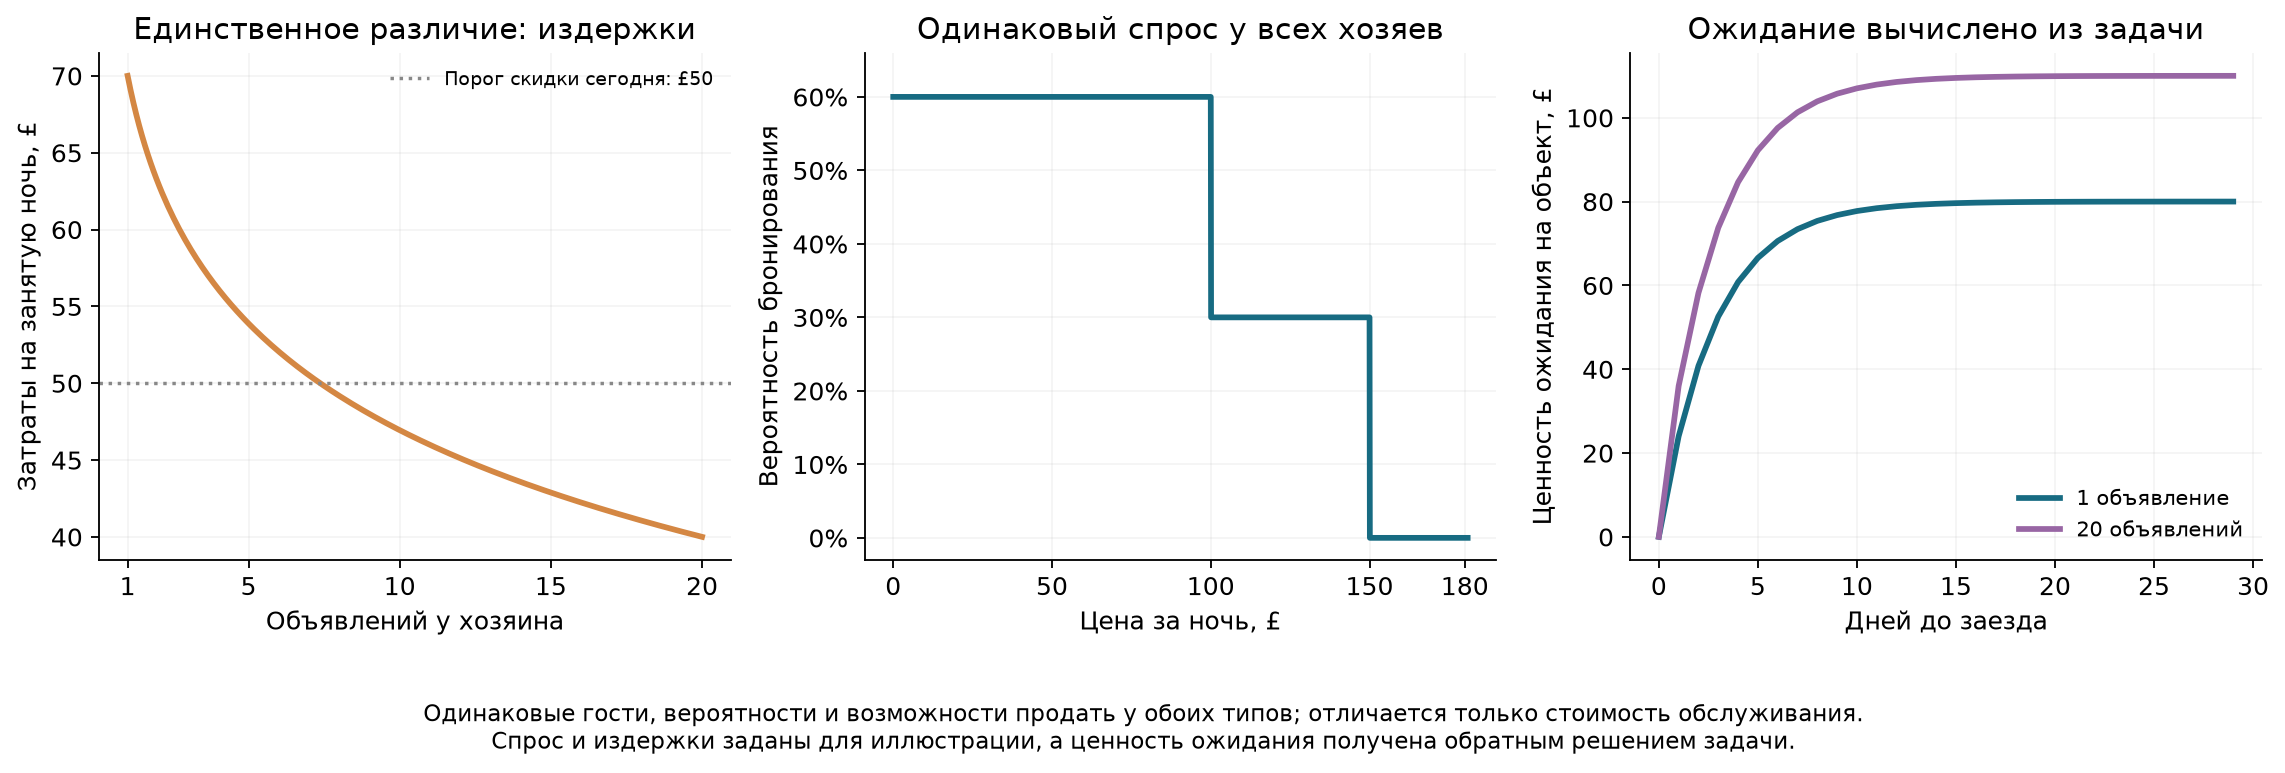

In [2]:
theory_figure('inputs')

## 3. Полная задача: решаем с последнего дня назад

Обозначим `V_r(c)` максимальную ожидаемую прибыль ещё свободного объекта, когда осталось `r` возможностей продать ночь. После окончания срока:

$$V_0(c)=0.$$

Сегодня, в день заезда, `r=1`. За день до заезда `r=2` и так далее. Для любой допустимой цены:

$$\boxed{V_r(c)=\max_{p\ge0}\{q(p)(p-c)+[1-q(p)]V_{r-1}(c)\}.}$$

Первое слагаемое — прибыль от продажи сейчас. Второе — ценность следующей возможности, если текущий гость не купил. При выборе цены хозяин учитывает, что проданную ночь нельзя продать снова.

Цены не ограничены заранее двумя вариантами. Но внутри каждого интервала спрос постоянен, а выручка растёт с ценой. Поэтому любая цена ниже £100 уступает £100, цена между £100 и £150 уступает £150, а цена выше £150 равносильна ожиданию. Глобальный максимум достигается среди трёх действий:

$$\begin{aligned}
\Pi_H(c,V)&=0{,}3(150-c)+0{,}7V,\\
\Pi_D(c,V)&=0{,}6(100-c)+0{,}4V,\\
\Pi_{wait}(V)&=V,
\end{aligned}$$

где `V=V_(r−1)(c)`. Берём действие с максимальной прибылью и повторяем расчёт для предыдущего дня. При равенстве двух прибылей выбираем полную цену. Для выбранного диапазона издержек полная цена всегда выгоднее чистого ожидания.

Ценность ожидания здесь **вычисляется из задачи**, а не задаётся отдельной экспонентой. Она может отличаться у хозяев только потому, что отличается стоимость обслуживания. Преимущества крупного хозяина в притоке будущих гостей не предполагается.

## 4. Когда скидка выгодна

Вычтем прибыль при полной цене из прибыли при скидке. Для общих обозначений `H=150`, `D=100`, `a=b=0,3`:

$$\boxed{\Delta\Pi(c,V)=b(D-c-V)-a(H-D).}$$

Здесь три составляющих:

- `b(D−c)` — прибыль от бюджетных гостей, которых привлекла скидка;
- `a(H−D)` — потеря выручки от гостей, которые заплатили бы полную цену;
- `bV` — потеря будущей возможности для дополнительно проданных ночей.

При выбранных параметрах:

$$\boxed{\Delta\Pi(c,V)=0{,}3(50-c-V).}$$

Скидка выгодна, только если `c+V<£50`. Перед самым заездом будущих возможностей нет, поэтому `V=0`. Тогда условие становится особенно простым:

$$\boxed{c<£50.}$$

У крупного хозяина `c=£40`, условие выполняется. У малого `c=£70`, не выполняется. Дополнительные гости при меньших издержках дают больше прибыли и окупают скидку гостям с высоким бюджетом. У малого хозяина дополнительной прибыли недостаточно.

## 5. Численное решение и политика цен

В день заезда:

| Хозяин | Издержки | Прибыль при цене £150 | Прибыль при цене £100 | Оптимальная цена |
|---|---:|---:|---:|---:|
| Малый | £70 | 0,3×80 = **£24** | 0,6×30 = £18 | **£150** |
| Крупный | £40 | 0,3×110 = £33 | 0,6×60 = **£36** | **£100** |

Это ожидаемая прибыль на ещё свободный объект. У крупного хозяина скидка даёт `£3` дополнительной ожидаемой прибыли, у малого уменьшает её на `£6`.

Теперь шаг назад. Ценность завтрашней возможности уже известна: `V₁(70)=£24`, `V₁(40)=£36`.

| Хозяин | Полная цена сейчас | Скидка сейчас | Оптимальная цена |
|---|---:|---:|---:|
| Малый | 24+0,7×24 = **£40,80** | 18+0,4×24 = £27,60 | **£150** |
| Крупный | 33+0,7×36 = **£58,20** | 36+0,4×36 = £50,40 | **£150** |

Заранее скидка невыгодна обоим: она отнимает будущую возможность продать ночь. При приближении заезда исчезает эта цена отказа от ожидания. Только у крупного хозяина после этого остаётся положительный выигрыш от скидки.

Для двух типов решение на любом конечном горизонте можно записать явно:

$$V_r(70)=80(1-0{,}7^r),\qquad r\ge1,$$

$$V_r(40)=110-74\cdot0{,}7^{r-1},\qquad r\ge1.$$

У малого хозяина оптимальная цена всегда £150. У крупного — £100 при последней возможности и £150 при двух или более оставшихся возможностях. Для всего диапазона `40≤c≤70` перед последней возможностью оптимальна полная цена. В последний день дисконтируют только хозяева с `c<50`, что при выбранной функции издержек соответствует `N>20^(2/3)≈7,37`.


Два уровня цены возникают из-за двух точек готовности платить. Одна возможность в день также является упрощением. Из модели не следует, что реальная цена Airbnb обязательно меняется на £50 или что реальная граница портфеля равна восьми объявлениям.

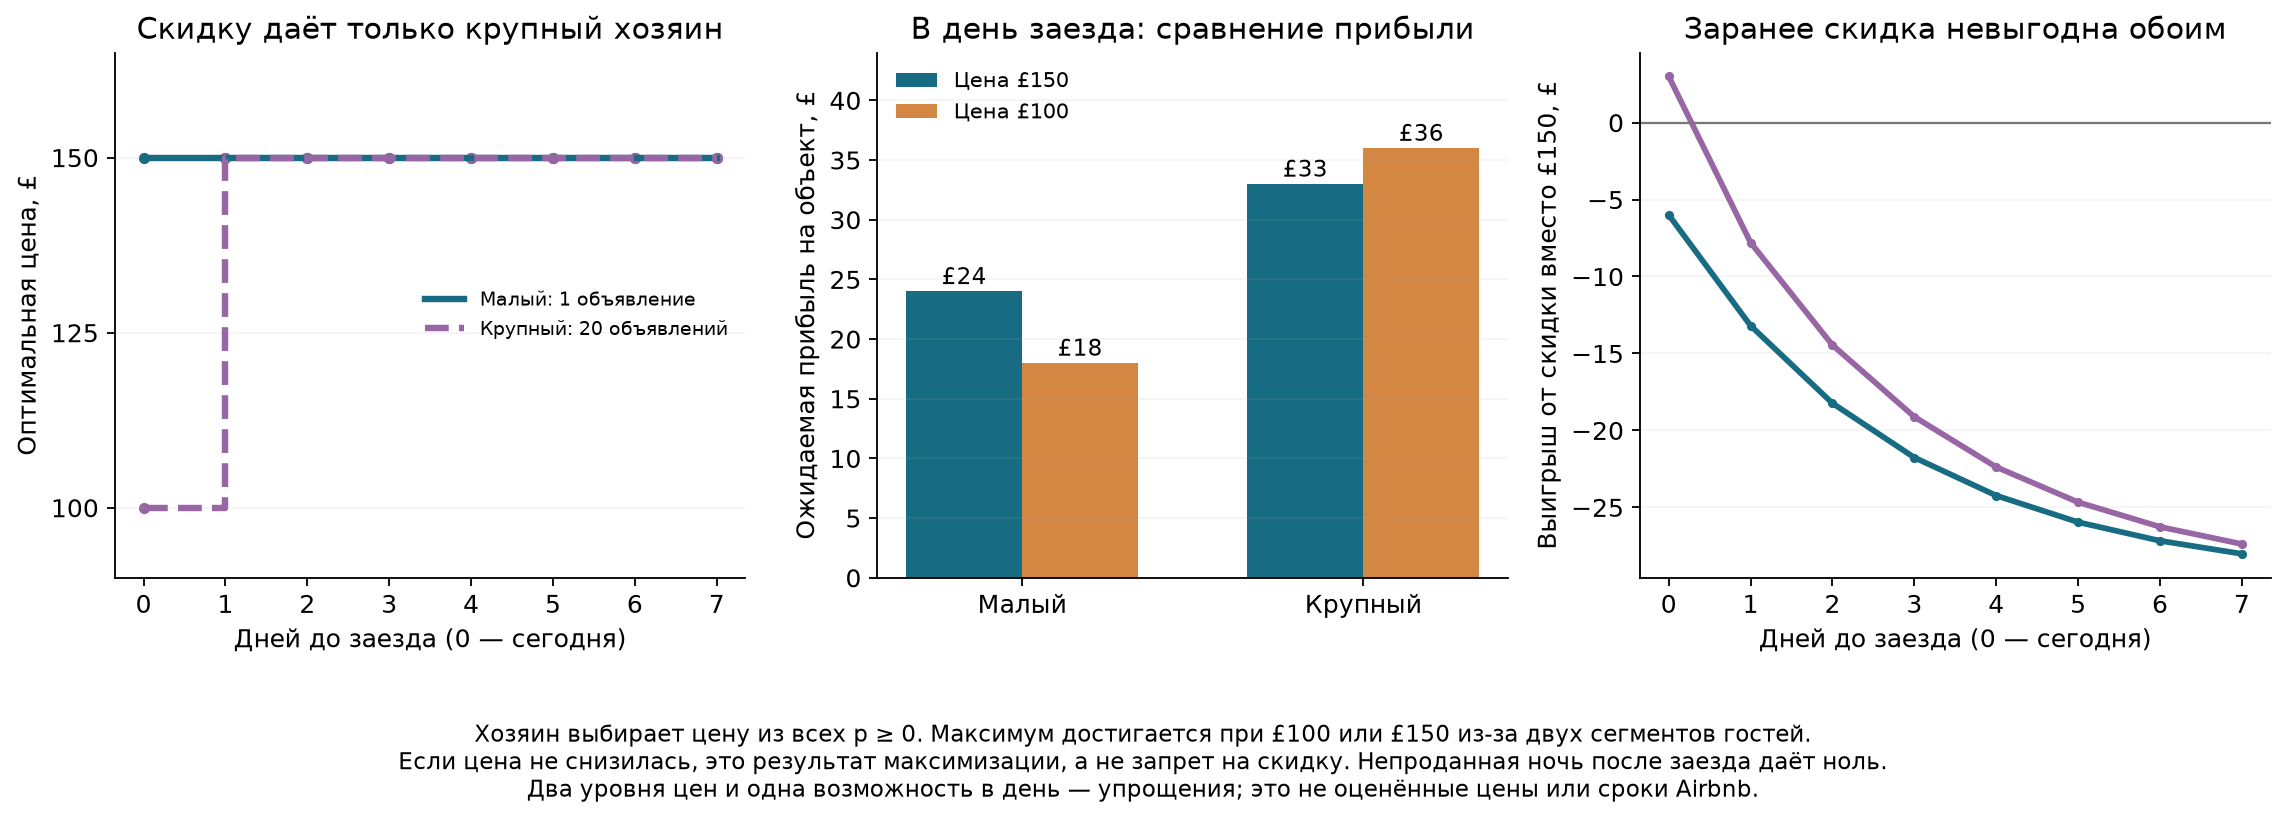

In [3]:
theory_figure('solution')

## 6. Проверяем, что результат вызван именно разницей издержек

Спрос и правила задачи не меняем. Если сделать издержки у обоих равными £70, оба сохраняют £150 в последний день. Если сделать издержки у обоих равными £40, оба снижают цену до £100. При одинаковых издержках решения совпадают на каждом шаге.

В исходном сравнении единственное различие хозяев — издержки. Поэтому разница в их решениях не объясняется большей готовностью к риску, отдельной функцией спроса или внешне назначенным преимуществом в ожидании.

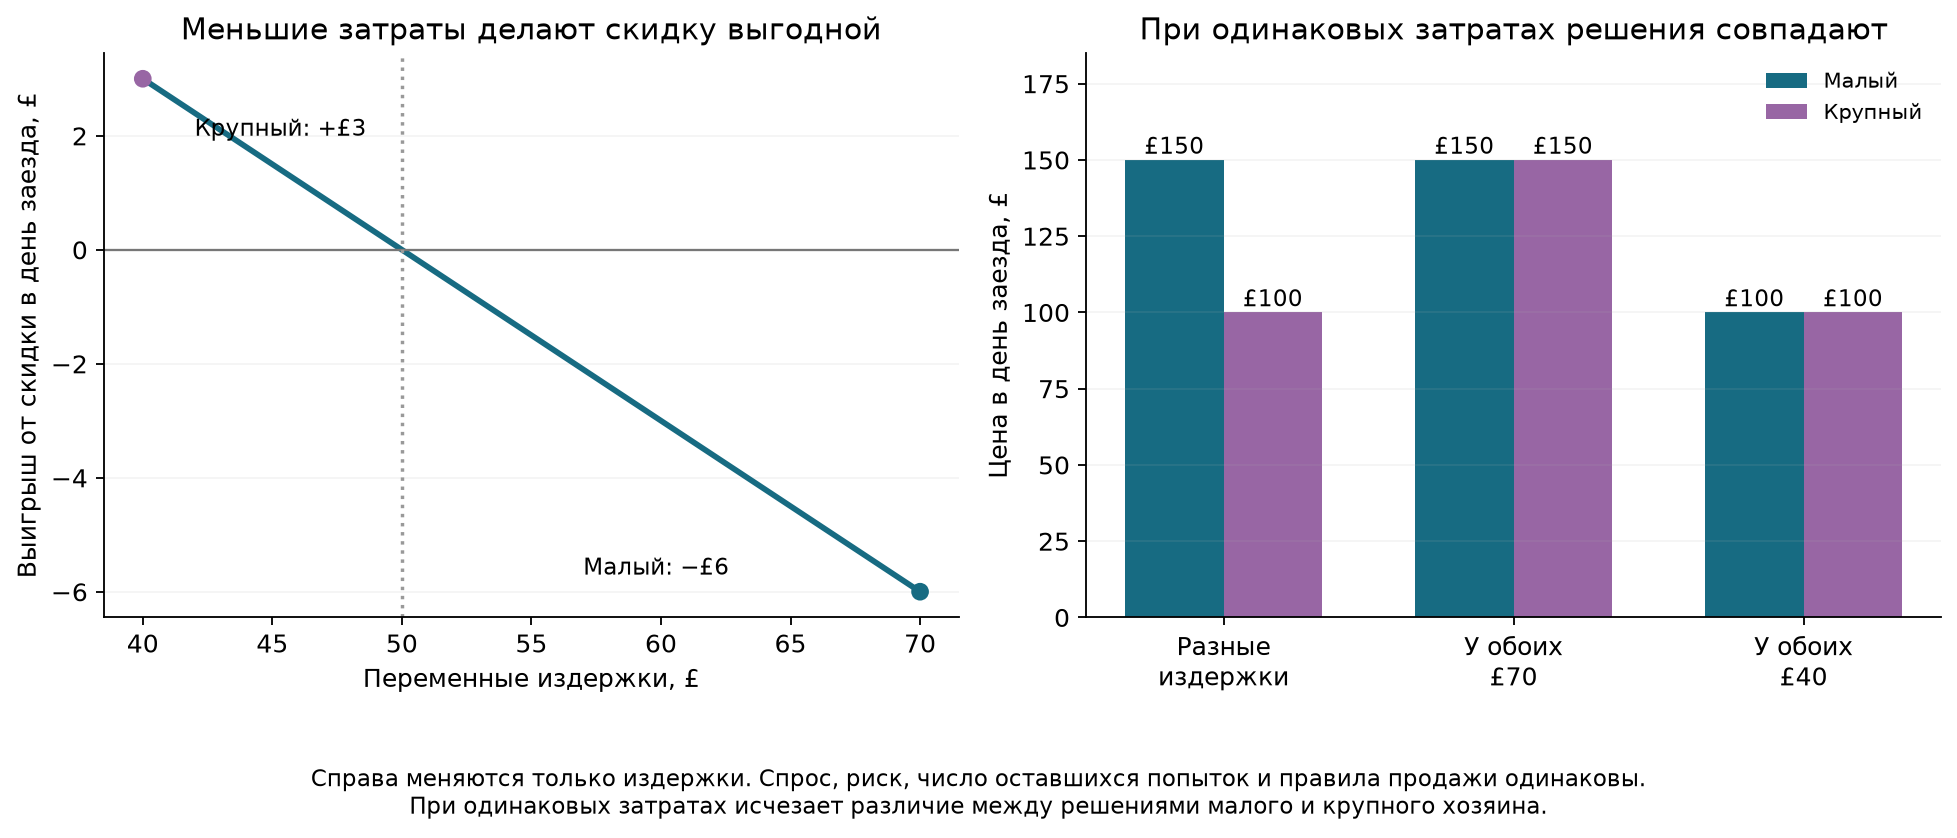

In [4]:
theory_figure('scenarios')

## 7. Что модель объясняет и чего пока не установили данные

Модель выводит нужный механизм: крупный хозяин, ещё не продавший ночь, снижает цену в день заезда, а малый сохраняет прежнюю. Разные издержки меняют выгоду от привлечения дополнительных бюджетных гостей. Непроданная ночь после заезда не имеет ценности.

Модель **не выводит положительную премию крупного хозяина заранее**: до последней возможности оба типа выбирают £150. Это отдельная часть рисунка OLS, которая здесь не объясняется. Кроме того, OLS сравнивала разные объявления и хозяев; изменения цены одного объекта во времени в ней не наблюдались. Нельзя считать, что она уже доказала описанную стратегию.

Вероятности гостей, их бюджеты и издержки заданы для иллюстрации и не оценены по Airbnb. Для эмпирической проверки механизма нужны повторные цены одного объекта, бронирования или отклики на цену и данные о затратах. Лог-полезность здесь не требуется: целевой результат получается при максимизации ожидаемой прибыли.

## 8. Воспроизведение и проверка решения

[Выполненный ноутбук](host_portfolio_economic_model.ipynb) содержит эту модель и три рисунка. Код: [helpers/host_portfolio_cost_model.py](helpers/host_portfolio_cost_model.py).

```bash
python helpers/host_portfolio_cost_model.py
```

Скрипт сохраняет политики цен для 20 размеров портфеля и 30 возможностей, таблицы примеров, все девять двухпериодных расписаний для двух типов, проверки и параметры в `results/host_portfolio_cost_model_*`. Графики сохранены в PNG и SVG.

Решение проверено тремя способами: сравнение максимума с плотной сеткой всех цен для 600 состояний; полный перебор 480 расписаний цен на горизонтах от одного до четырёх дней; сверка рекурсии с явной формулой ценности ожидания. Также проверены разложение выигрыша от скидки и совпадение политик при одинаковых издержках. Основной эмпирический ноутбук и модели прогноза не менялись.

In [5]:
display(pd.Series(theory_method['checks'], name='Проверка решения'))

unrestricted_price_grid_states             600
exhaustive_schedule_comparisons             16
enumerated_schedules                       480
closed_form_values_match                  True
discount_gain_decomposition_matches       True
small_never_discounts                     True
large_discounts_only_final_day            True
identical_costs_imply_identical_policy    True
Name: Проверка решения, dtype: object